Epoch 1/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.6749 - loss: 1.2034 - val_accuracy: 0.9374 - val_loss: 0.3221
Epoch 2/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9685 - loss: 0.1755 - val_accuracy: 0.9956 - val_loss: 0.0725
Epoch 3/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9976 - loss: 0.0438 - val_accuracy: 1.0000 - val_loss: 0.0207
Epoch 4/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9999 - loss: 0.0153 - val_accuracy: 1.0000 - val_loss: 0.0120
Epoch 5/5
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9999 - loss: 0.0073 - val_accuracy: 1.0000 - val_loss: 0.0064
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8148 - loss: 0.8279
Test Loss: 0.8279199600219727
Test Accuracy: 0.8148354887962341


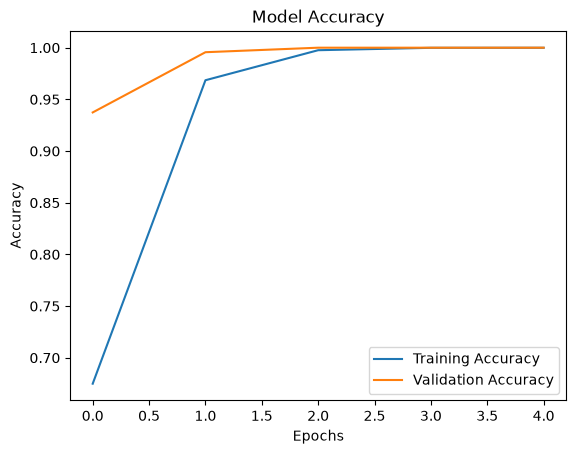

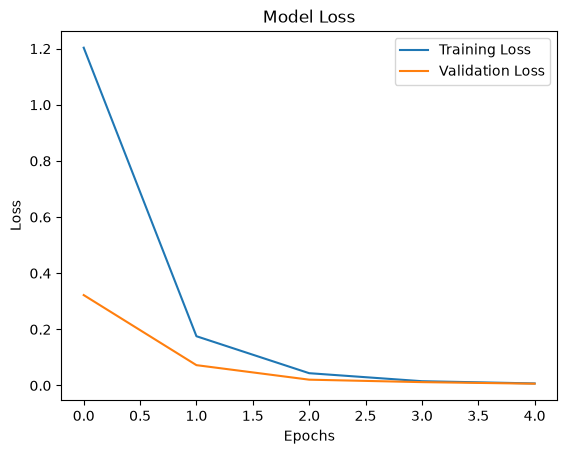

In [1]:

# PRACTICAL 2C: CNN FOR SIGN LANGUAGE MNIST

# 1. Import libraries
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

# 2. Load offline dataset
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

# 3. Separate images and labels
x_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

x_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

# 4. Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

# 5. Reshape images for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# 6. Create CNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(25, activation='softmax')
])

# 7. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 8. Train model
history = model.fit(
    x_train, y_train,
    epochs=5,
    validation_split=0.1
)

# 9. Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 10. Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 11. Plot loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


Great! This is Practical 2C – CNN for Sign Language MNIST.

It is almost identical to Practical 2B (CNN for handwritten digits). The main differences are the dataset and the number of output classes.

There is one important correction in your code: Sign Language MNIST has 24 classes, not 25, because letters J and Z are excluded.

## 1. Corrected complete code

I've also corrected the labels so that they become 0–23. This is important because your output layer has 24 neurons.

```
# --------------------------------------------------# PRACTICAL 2C: CNN FOR SIGN LANGUAGE MNIST# --------------------------------------------------# STAGE 1: Loading and preprocessing data# 1. Import librariesimport tensorflow as tfimport pandas as pdimport matplotlib.pyplot as plt# 2. Load offline datasettrain_data = pd.read_csv("sign_mnist_train.csv")test_data = pd.read_csv("sign_mnist_test.csv")# 3. Separate images and labelsx_train = train_data.iloc[:, 1:].values# Copy labels so we can modify themy_train = train_data.iloc[:, 0].values.copy()x_test = test_data.iloc[:, 1:].valuesy_test = test_data.iloc[:, 0].values.copy()# 4. Correct labels (J and Z are excluded)y_train[y_train > 9] -= 1y_test[y_test > 9] -= 1# 5. Normalize imagesx_train = x_train / 255.0x_test = x_test / 255.0# 6. Reshape images for CNNx_train = x_train.reshape(-1, 28, 28, 1)x_test = x_test.reshape(-1, 28, 28, 1)
```

## 2. Understand the four stages

### Stage 1 – Loading and preprocessing

```
x_train = train_data.iloc[:, 1:].valuesy_train = train_data.iloc[:, 0].values.copy()
```

- `x_train` contains image pixels.
- `y_train` contains the alphabet labels.
- First column = label.
- Remaining 784 columns = image pixels.

Label correction:

```
y_train[y_train > 9] -= 1y_test[y_test > 9] -= 1
```

Sign Language MNIST excludes J and Z.

The original labels are 0–25, with 9 and 25 missing. This correction shifts labels greater than 9 down by one, making the classes 0–23.

Normalization:

```
x_train = x_train / 255.0
```

Converts pixel values from 0–255 into 0–1.

Reshaping:

```
x_train = x_train.reshape(-1, 28, 28, 1)
```

Converts 784 pixel values into a 28 × 28 grayscale image.

### Stage 2 – Define CNN architecture

[Notes about convolutional neural networks -](https://images.openai.com/static-rsc-4/1SJH3kJMLNOmYSYV9oJDnaW5LMAC9hmE6xh5rFxIrccG0SgELiErDu3DV-Vk0C8z7Fi5ijTX0WdJqcGYNoOJhNuM6iUVBjVP_qtQLG6y3_Kcx6DnNpzEzJO6wLwrHq9ksNQ9xYv0aFo0lHu3pvHrt_gJxQyyExTqND0etuguVIQ?purpose=inline)

[joapen.com](https://joapen.com/blog/2021/05/07/notes-about-convolutional-neural-networks/?utm_source=chatgpt.com)

| Layer               | Purpose                      |
| ------------------- | ---------------------------- |
| Input (28, 28, 1)   | Receives hand gesture image  |
| Conv2D (32 filters) | Extracts image features      |
| MaxPooling2D        | Reduces image size           |
| Flatten             | Converts features into 1D    |
| Dense (128)         | Learns patterns              |
| Dense (24)          | Predicts 24 alphabet classes |

The most important difference from Practical 2B is:

```
tf.keras.layers.Dense(24, activation='softmax')
```

Because there are 24 alphabet classes.

### Stage 3 – Compile and train

```
model.compile(    optimizer='adam',    loss='sparse_categorical_crossentropy',    metrics=['accuracy'])
```

- Adam = optimizer.
- Loss = measures prediction error.
- Accuracy = measures correct predictions.

```
history = model.fit(    x_train, y_train,    epochs=5,    validation_split=0.1)
```

- 5 epochs = model sees training data five times.
- 10% of training data is used for validation.

### Stage 4 – Evaluate performance

```
loss, accuracy = model.evaluate(x_test, y_test)
```

Tests the model using unseen hand gesture images.

The accuracy graph should generally increase, while the loss graph should generally decrease.

## 3. Difference between Practical 2B and 2C

| Feature          | Practical 2B       | Practical 2C        |
| ---------------- | ------------------ | ------------------- |
| Dataset          | MNIST              | Sign Language MNIST |
| Images           | Handwritten digits | Hand gestures       |
| Image size       | 28 × 28            | 28 × 28             |
| Input shape      | 28 × 28 × 1        | 28 × 28 × 1         |
| Output neurons   | 10                 | 24                  |
| Label correction | Not needed         | J and Z correction  |

## 4. Important viva questions

Q1. Why do we use CNN?

CNN is used for image classification because it can automatically extract image features.

Q2. Why are there 24 output neurons?

Because Sign Language MNIST contains 24 classes, excluding J and Z.

Q3. Why do we correct labels?

To convert the original labels into continuous class numbers from 0 to 23.

Q4. What is Conv2D?

It extracts features such as edges, curves and shapes from images.

Q5. What is MaxPooling?

It reduces the feature-map size while retaining important information.

Q6. Why do we use Softmax?

To calculate the probability of each alphabet class.

Q7. What is the difference between MNIST and Sign Language MNIST?

MNIST classifies handwritten digits from 0–9, while Sign Language MNIST classifies hand gestures representing 24 letters.

## 5. Remember these numbers

# 784

Input pixels

# 24

Output classes

# 28 × 28

Image dimensions

# 5

Training epochs

Exam tip: Remember the CNN sequence:

Conv2D → MaxPooling → Flatten → Dense → Softmax

That is the core architecture you need to explain in your practical exam.